<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/brcanceripynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 4: Breast Cancer Diagnosis
**Aim:** Develop a breast cancer classification model using medical diagnostic data.

This experiment uses the built-in **Breast Cancer Wisconsin** dataset from `scikit-learn`. A Logistic Regression classifier is trained to classify tumors as **malignant** or **benign**.

In [2]:
import pandas as pd


## 1. Load the Dataset


In [3]:
df=pd.read_excel('exp4.xlsx')
df.to_csv("exp4.csv",index=False)

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,NaN,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,NaN,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.shape

(569, 32)

## 2. Check the Dataset

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                563 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         565 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,563.000000,569.000000,565.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.661949,20.665290,91.969033,653.792540,0.096360,0.103848,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,13.298223,24.631507,24.298981,352.774933,0.014064,0.052368,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,419.250000,0.086370,0.064500,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,546.100000,0.095870,0.092280,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.850000,21.800000,104.100000,782.650000,0.105300,0.130300,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,320.000000,520.000000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [9]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,6
smoothness_mean,0
compactness_mean,4
concavity_mean,0
concave points_mean,0


In [12]:
df=df.dropna()
df.isnull().sum()

np.int64(0)

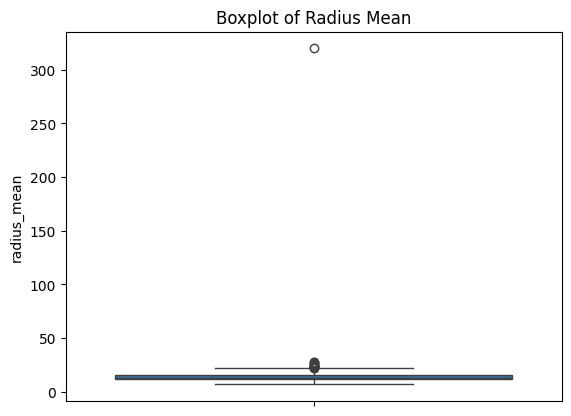

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(df["radius_mean"])
plt.title('Boxplot of Radius Mean')

plt.show()

In [19]:
Q1=df["radius_mean"].quantile(0.25)
Q3=df["radius_mean"].quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("Q1=",Q1)
print("Q3=",Q3)
print("IQR=",IQR)
print("Lower Bound=",lower_bound)
print("Upper Bound=",upper_bound)


outliers=df[(df["radius_mean"]<lower_bound)|(df["radius_mean"]>upper_bound)]
print("Outliers:")
print(outliers)
df=df[(df["radius_mean"]>=lower_bound)&(df["radius_mean"]<=upper_bound)]

Q1= 11.637500000000001
Q3= 15.46
IQR= 3.8225
Lower Bound= 5.903750000000001
Upper Bound= 21.19375
Outliers:
          id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
272  8910988         M        21.75         20.99           147.3     1491.0   
368  9011971         M        21.71         17.25           140.9     1546.0   
372  9012795         M        21.37         15.10           141.3     1386.0   
393   903516         M        21.61         22.28           144.4     1407.0   
564   926424         M        21.56         22.39           142.0     1479.0   

     smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
272          0.09401           0.19610          0.2195              0.10880   
368          0.09384           0.08562          0.1168              0.08465   
372          0.10010           0.15150          0.1932              0.12550   
393          0.11670           0.20870          0.2810              0.15620   
564          0.1

In [21]:
numerical_columns=df.select_dtypes(include=['float64','int64']).columns
print(numerical_columns)

Index(['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


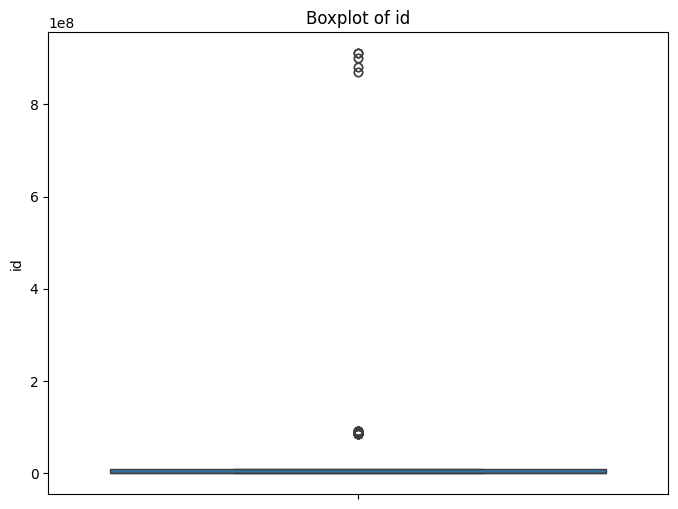

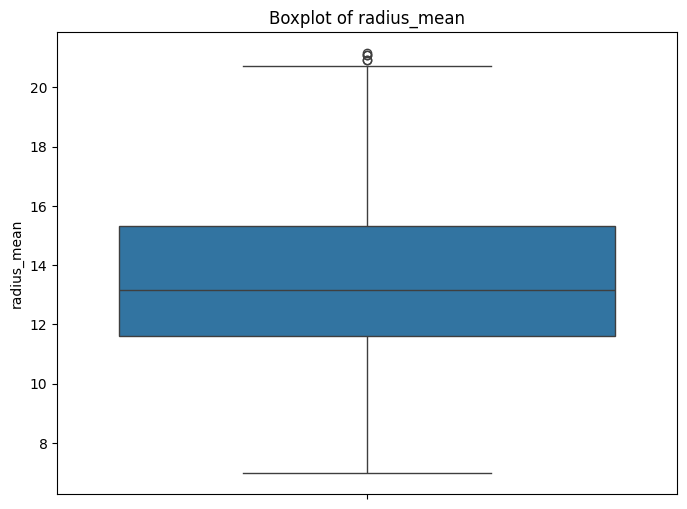

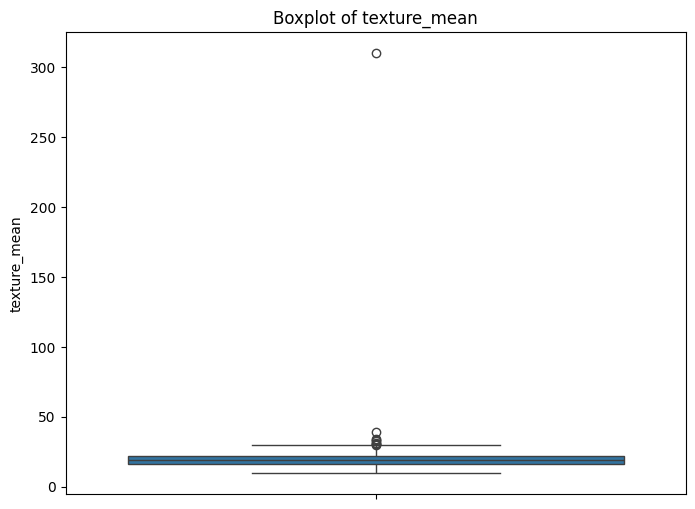

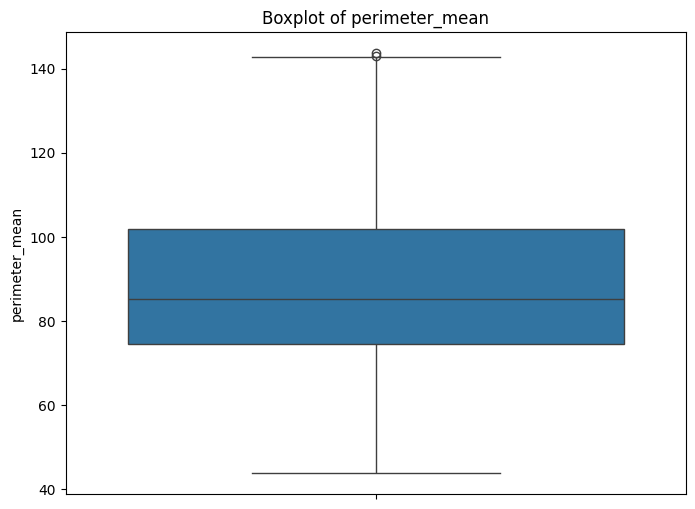

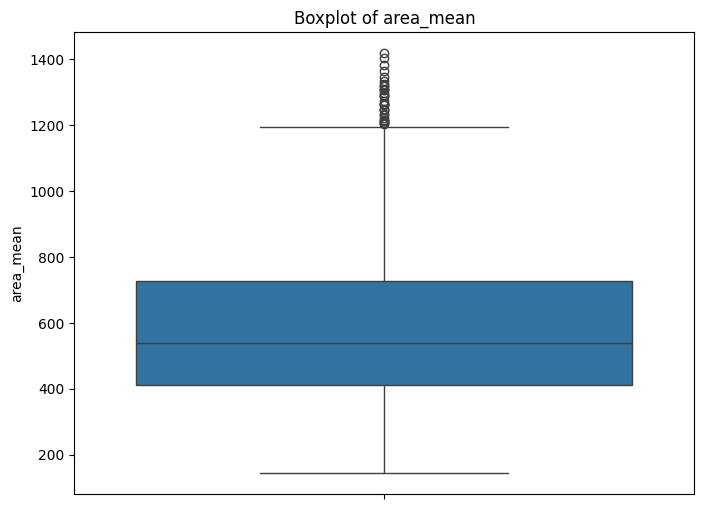

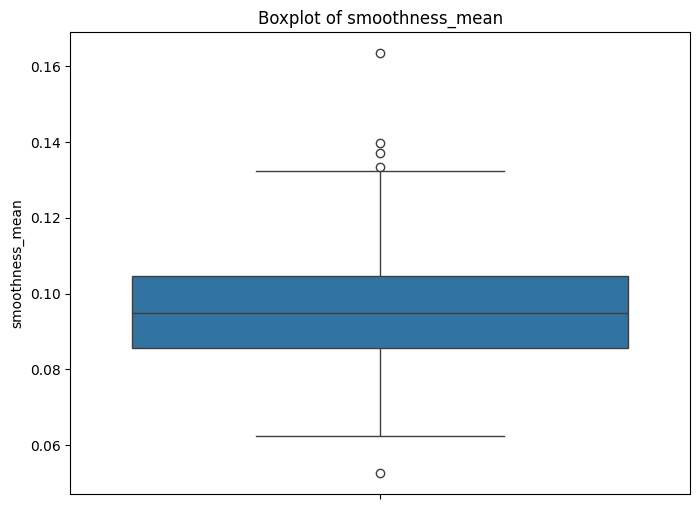

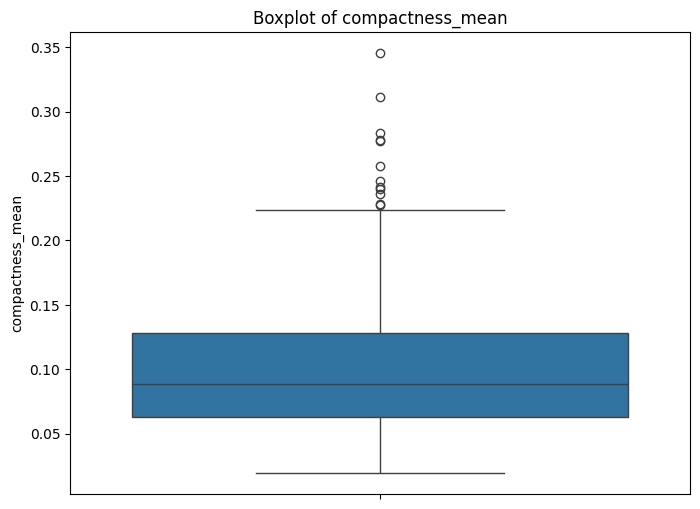

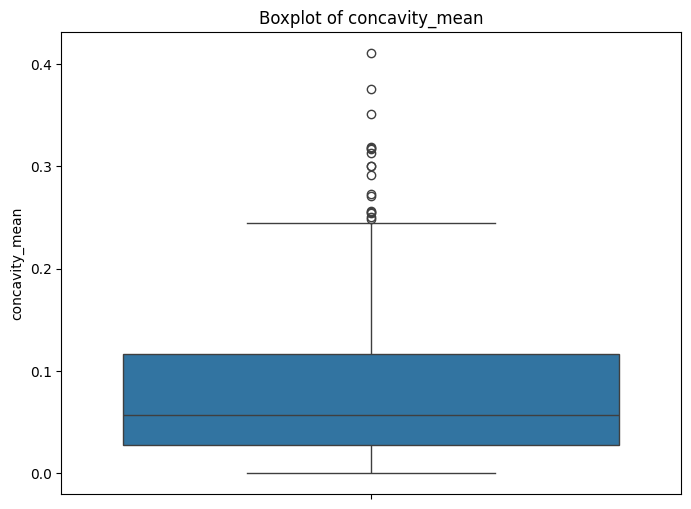

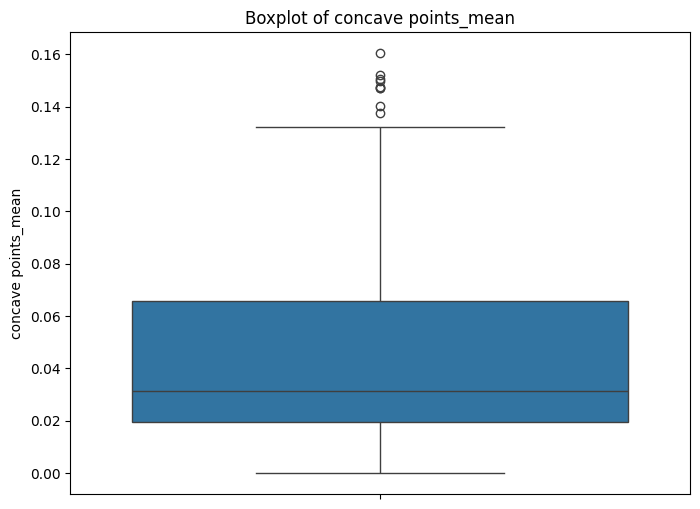

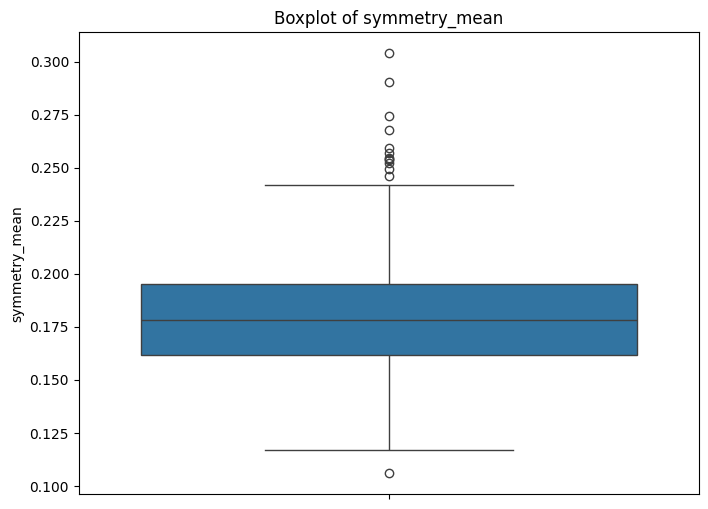

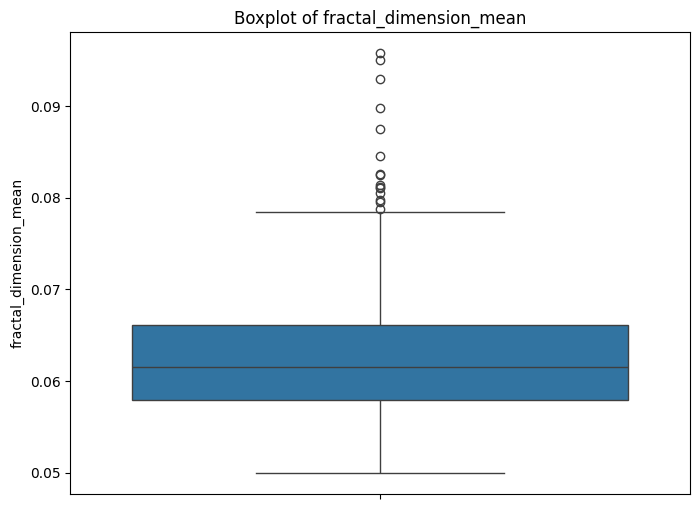

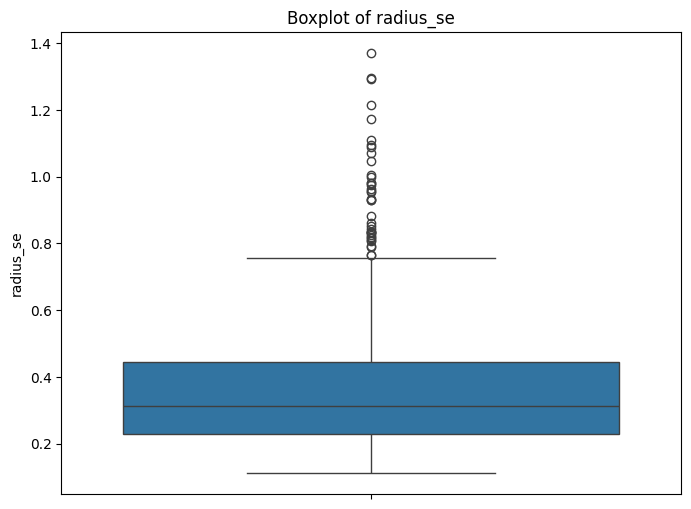

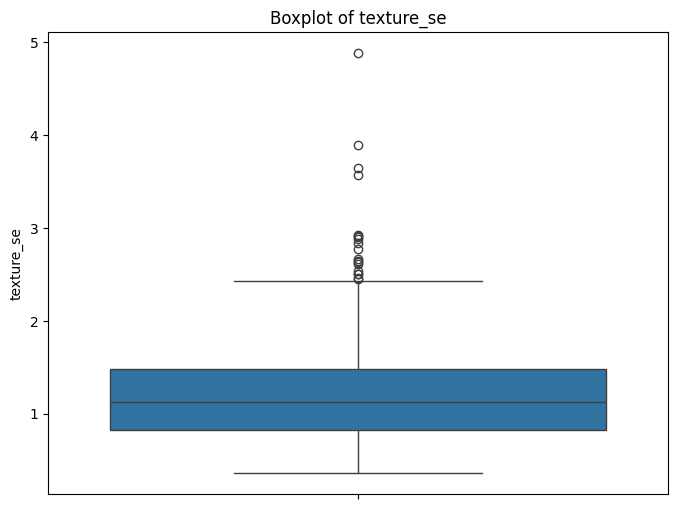

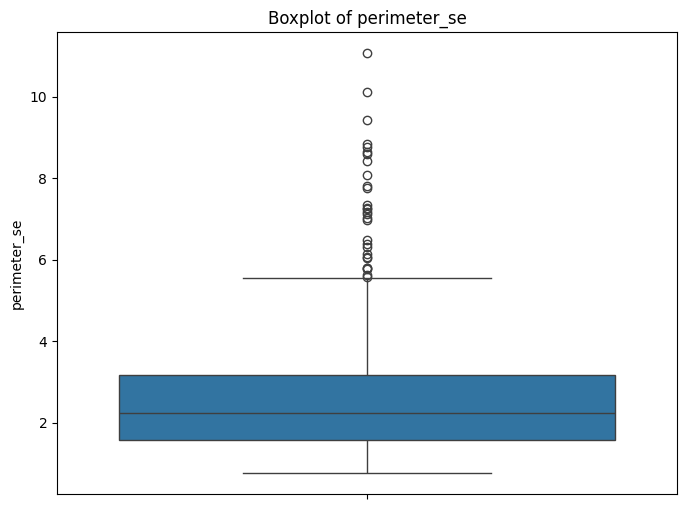

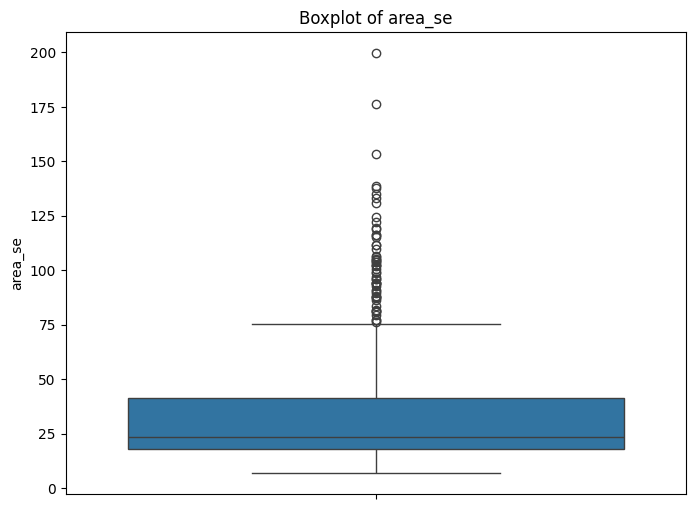

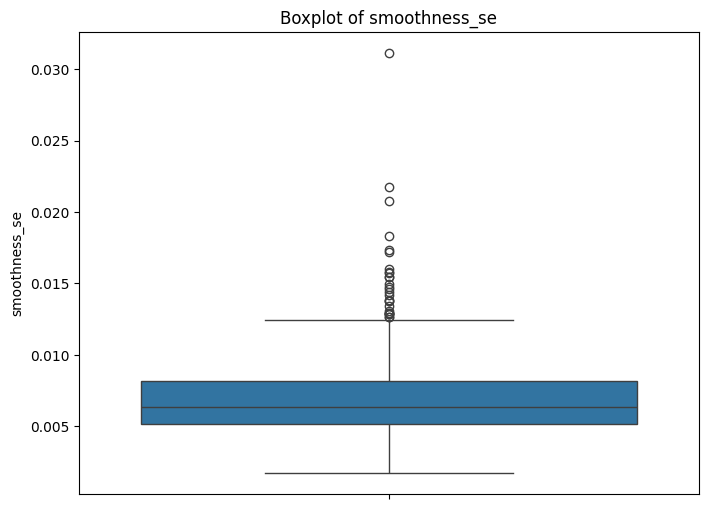

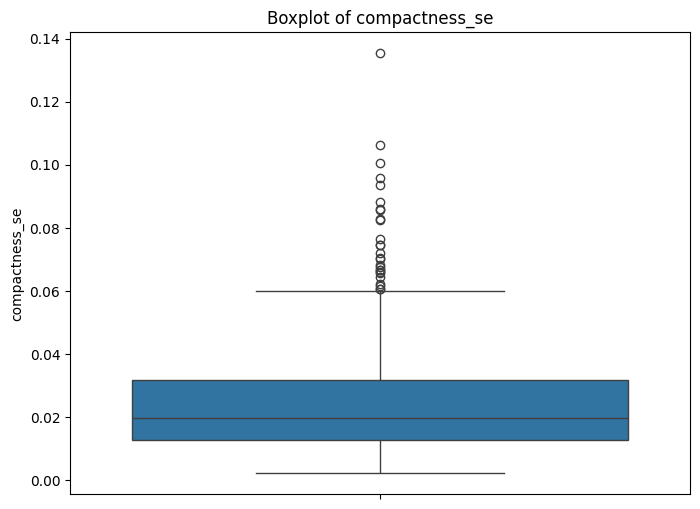

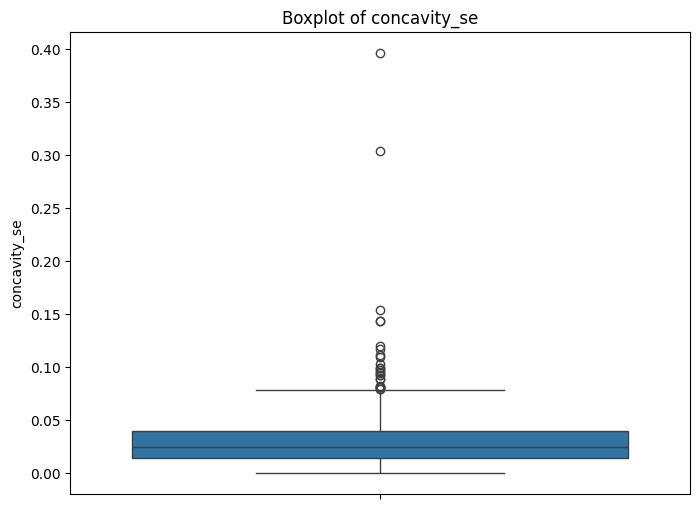

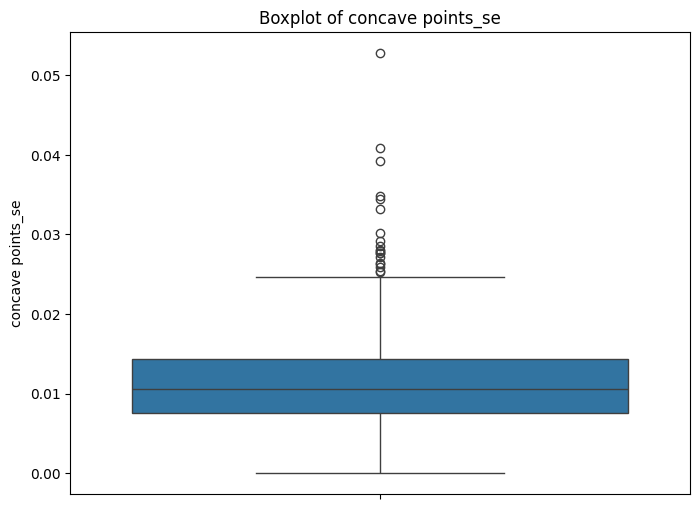

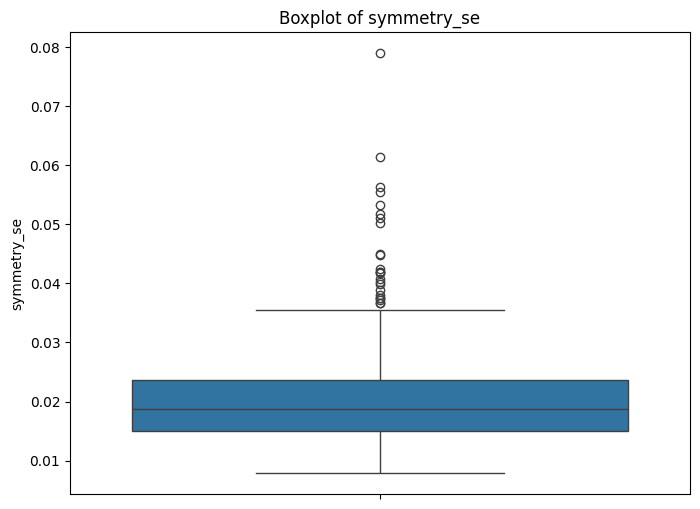

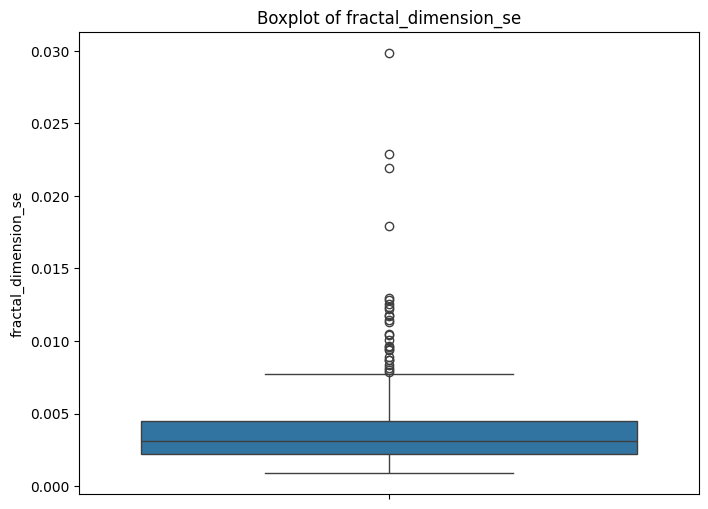

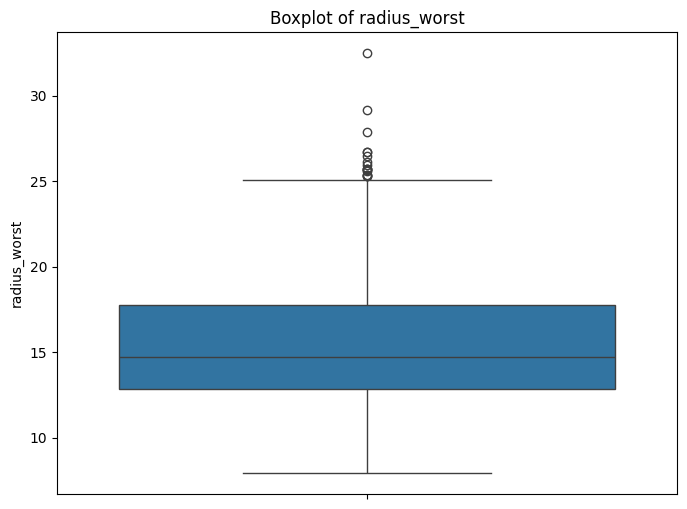

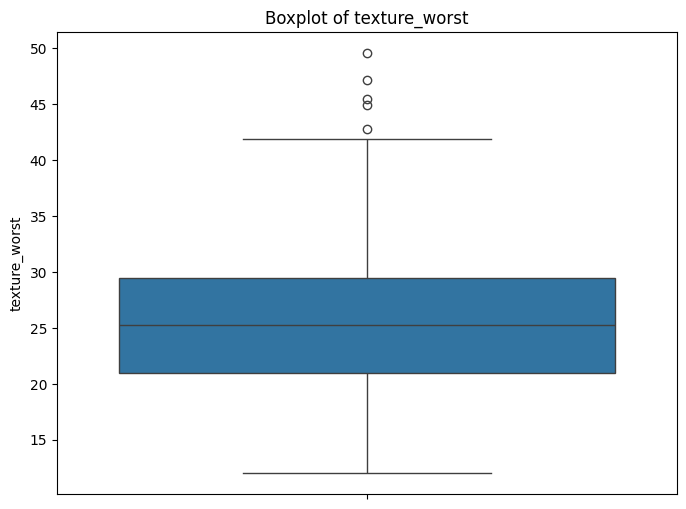

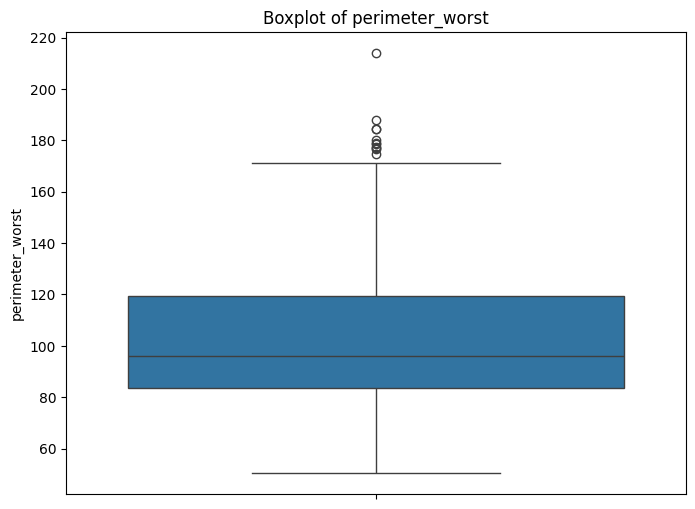

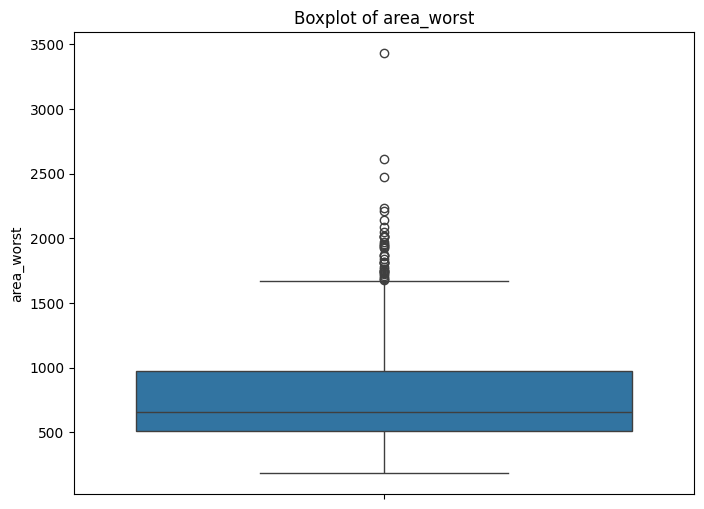

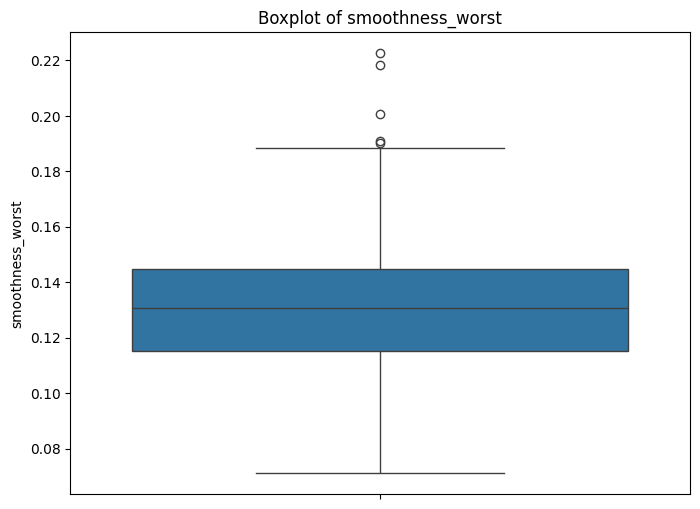

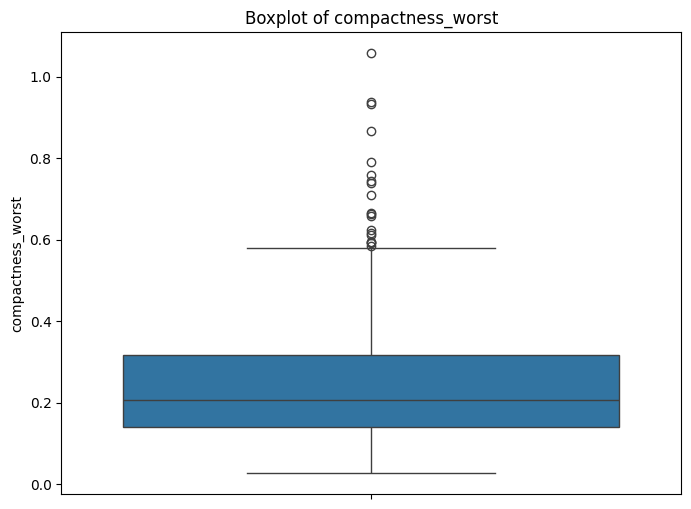

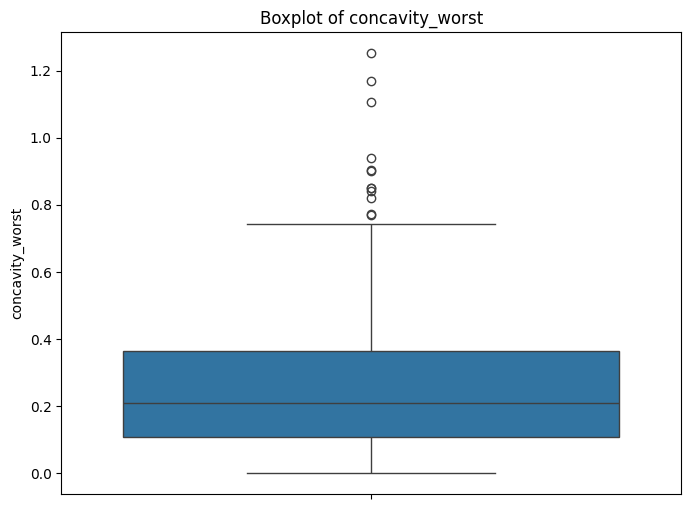

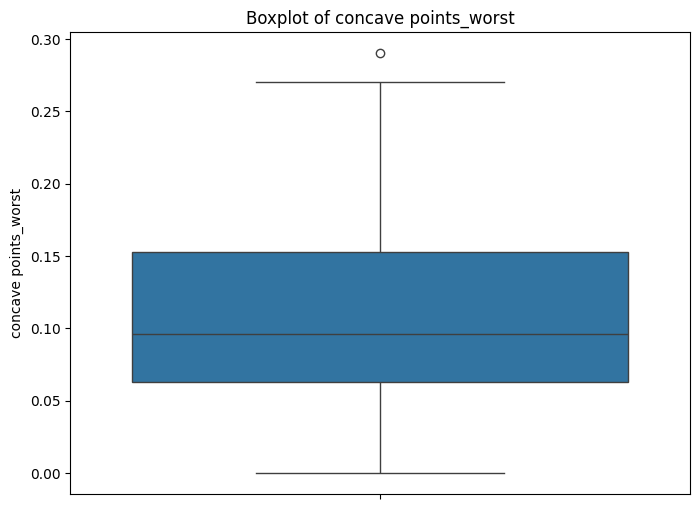

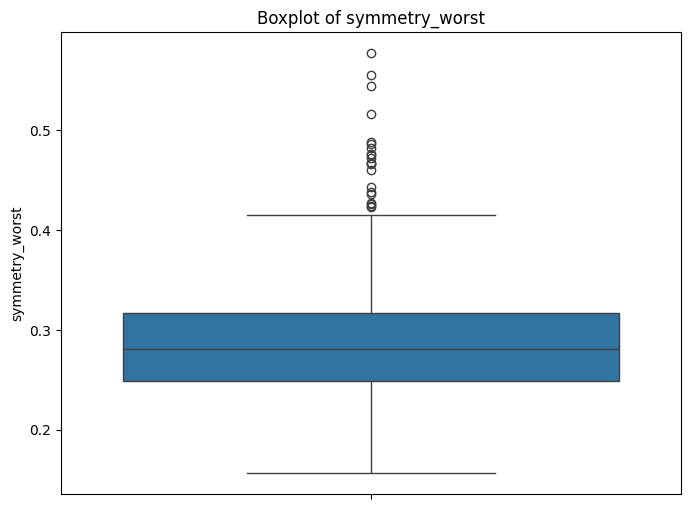

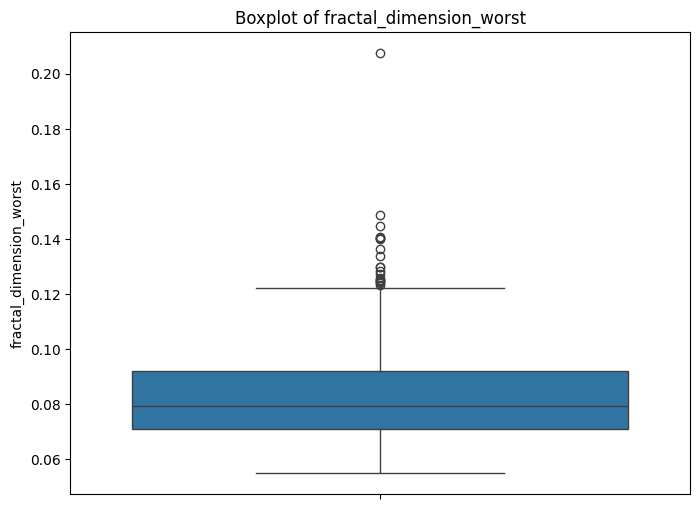

In [22]:
for column in numerical_columns:
    plt.figure(figsize=(8,6))
    sns.boxplot(df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

In [24]:
for col in numerical_columns:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)
  IQR=Q3-Q1

  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  df[col]=df[col].clip(
      lower=lower_bound,
      upper=upper_bound
      )

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 539 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       539 non-null    float64
 1   diagnosis                539 non-null    object 
 2   radius_mean              539 non-null    float64
 3   texture_mean             539 non-null    float64
 4   perimeter_mean           539 non-null    float64
 5   area_mean                539 non-null    float64
 6   smoothness_mean          539 non-null    float64
 7   compactness_mean         539 non-null    float64
 8   concavity_mean           539 non-null    float64
 9   concave points_mean      539 non-null    float64
 10  symmetry_mean            539 non-null    float64
 11  fractal_dimension_mean   539 non-null    float64
 12  radius_se                539 non-null    float64
 13  texture_se               539 non-null    float64
 14  perimeter_se             539 no

In [26]:
from sklearn.preprocessing import LabelEncoder

label_encoder=LabelEncoder()
df['diagnosis']=label_encoder.fit_transform(df['diagnosis'])

In [27]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

## 3. Split Data into Training and Testing Sets

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## 4. Feature Scaling

In [29]:
#Feature scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

## 5. Train Model

In [42]:
X_train = pd.DataFrame(X_train, columns=numerical_columns)

print(X_train.head())

         id  radius_mean  texture_mean  perimeter_mean  area_mean  \
0 -0.552346    -0.670010     -0.709363       -0.651964  -0.686402   
1 -0.556439     2.314635      1.090886        2.350740   2.165407   
2  0.622589    -0.478759      2.643874       -0.560571  -0.521744   
3 -0.552612     0.146857      0.352760        0.149262   0.039340   
4 -0.552648    -0.297233     -0.816549       -0.301546  -0.369555   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0         1.334679         -0.119412       -0.535257            -0.373319   
1         0.416642          1.351914        2.612045             2.645845   
2        -1.382254         -1.388991       -1.189979            -1.321956   
3        -0.447526          0.273909       -0.415298            -0.395732   
4        -0.364827         -0.334580       -0.297176            -0.389674   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0       0.222497  ...     -0.570338      -0.624877 

## 6. Make Predictions &  Evaluate the Model, Matrix Visualisation

### Model Training and Evaluation
I will now train four different classification models: Logistic Regression, Support Vector Machine (SVM), Decision Tree, and Random Forest. For each model, I will evaluate its performance using accuracy, a classification report, and a confusion matrix.

#### 1. Logistic Regression

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Logistic Regression Accuracy: 0.9629629629629629

Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97        65
           1       0.98      0.93      0.95        43

    accuracy                           0.96       108
   macro avg       0.97      0.96      0.96       108
weighted avg       0.96      0.96      0.96       108



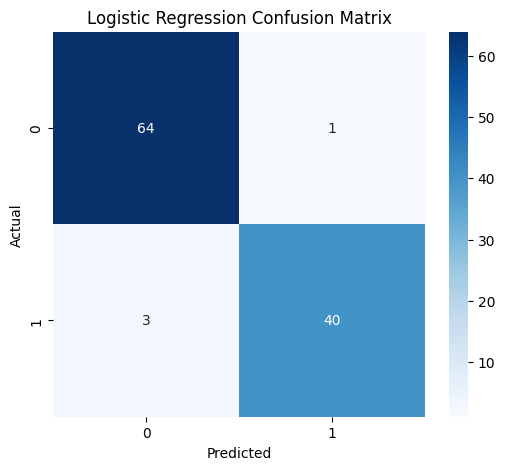

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, max_iter=200)
log_reg_model.fit(X_train, y_train)

# Make predictions
y_pred_log_reg = log_reg_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log_reg))
print("\nLogistic Regression Classification Report:\n", classification_report(y_test, y_pred_log_reg))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_log_reg), annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### 2. Support Vector Machine (SVM)

SVM Accuracy: 0.9537037037037037

SVM Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.96        65
           1       1.00      0.88      0.94        43

    accuracy                           0.95       108
   macro avg       0.96      0.94      0.95       108
weighted avg       0.96      0.95      0.95       108



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


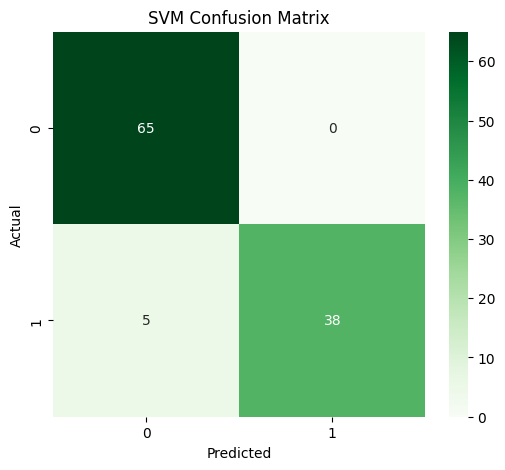

In [32]:
from sklearn.svm import SVC

# Initialize and train the SVM model
svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nSVM Classification Report:\n", classification_report(y_test, y_pred_svm))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens')
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### 3. Decision Tree

Decision Tree Accuracy: 0.9259259259259259

Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.95      0.94        65
           1       0.93      0.88      0.90        43

    accuracy                           0.93       108
   macro avg       0.93      0.92      0.92       108
weighted avg       0.93      0.93      0.93       108



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


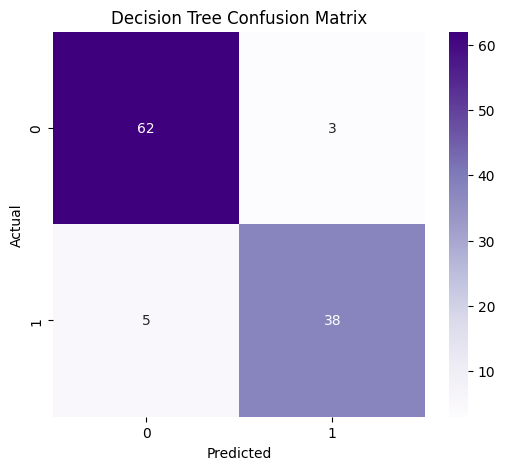

In [33]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nDecision Tree Classification Report:\n", classification_report(y_test, y_pred_dt))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Purples')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### 4. Random Forest

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Random Forest Accuracy: 0.8981481481481481

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92        65
           1       0.94      0.79      0.86        43

    accuracy                           0.90       108
   macro avg       0.91      0.88      0.89       108
weighted avg       0.90      0.90      0.90       108



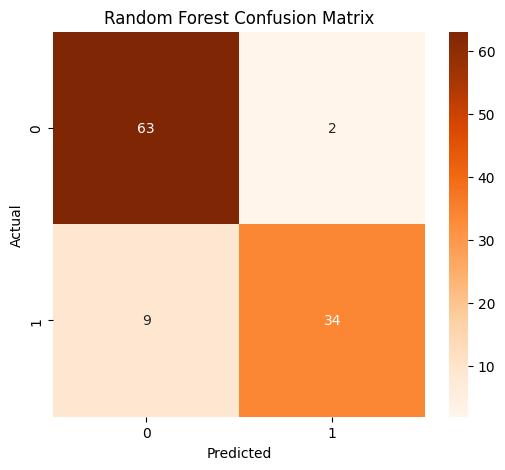

In [34]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nRandom Forest Classification Report:\n", classification_report(y_test, y_pred_rf))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Oranges')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Model Performance Comparison (Accuracy in Percentages)

In [35]:
# Calculate accuracies in percentages
log_reg_accuracy = accuracy_score(y_test, y_pred_log_reg) * 100
svm_accuracy = accuracy_score(y_test, y_pred_svm) * 100
dt_accuracy = accuracy_score(y_test, y_pred_dt) * 100
rf_accuracy = accuracy_score(y_test, y_pred_rf) * 100

# Print the results
print(f"Logistic Regression Accuracy: {log_reg_accuracy:.2f}%")
print(f"Support Vector Machine Accuracy: {svm_accuracy:.2f}%")
print(f"Decision Tree Accuracy: {dt_accuracy:.2f}%")
print(f"Random Forest Accuracy: {rf_accuracy:.2f}%")

# Create a dictionary for easier comparison
model_accuracies = {
    "Logistic Regression": log_reg_accuracy,
    "SVM": svm_accuracy,
    "Decision Tree": dt_accuracy,
    "Random Forest": rf_accuracy
}

# Find the best performing model
best_model = max(model_accuracies, key=model_accuracies.get)
best_accuracy = model_accuracies[best_model]

print(f"\nThe best performing model is {best_model} with an accuracy of {best_accuracy:.2f}%")

Logistic Regression Accuracy: 96.30%
Support Vector Machine Accuracy: 95.37%
Decision Tree Accuracy: 92.59%
Random Forest Accuracy: 89.81%

The best performing model is Logistic Regression with an accuracy of 96.30%


### Model Theory Summary

Here's a brief theoretical overview of the classification models used:

#### 1. Logistic Regression
Logistic Regression is a linear model used for binary classification. Despite its name, it's a classification algorithm, not a regression one. It uses the logistic function (sigmoid function) to model the probability of a binary outcome. The output probability is then mapped to a class label (0 or 1).

#### 2. Support Vector Machine (SVM)
SVM is a powerful and versatile machine learning model capable of performing linear or non-linear classification, regression, and even outlier detection. For classification, it works by finding the optimal hyperplane that best separates the data points of different classes in the feature space. The goal is to maximize the margin (the distance between the hyperplane and the nearest data points from each class, called support vectors).

#### 3. Decision Tree
Decision Trees are non-parametric supervised learning methods used for classification and regression. They work by creating a model that predicts the value of a target variable by learning simple decision rules inferred from the data features. The tree structure consists of internal nodes (features/attributes), branches (decision rules), and leaf nodes (outcomes/class labels).

#### 4. Random Forest
Random Forest is an ensemble learning method that builds multiple decision trees during training and outputs the class that is the mode of the classes (classification) or mean prediction (regression) of the individual trees. It's an extension of decision trees that improves accuracy and reduces overfitting by aggregating the results of many trees, each trained on a random subset of features and data.

####Logistic Regression: 96.3%
####Support Vector Machine (SVM): 95.4%
####Decision Tree: 92.6%
####Random Forest: 89.8%

All tasks have been completed. I have successfully loaded and preprocessed the data, handled outliers, and trained four different machine learning models: Logistic Regression, SVM, Decision Tree, and Random Forest. Their performance metrics (accuracy, classification reports, and confusion matrices) have been displayed and summarized.


##The best performing model is Logistic Regression with an accuracy of 96.30%

### Visualizing Decision Boundary for the Best Model (Logistic Regression)

Since our dataset has many features, directly visualizing decision boundaries is not straightforward. To overcome this, I'll use Principal Component Analysis (PCA) to reduce the data to two principal components. This will allow us to plot the data in a 2D space and visualize the decision boundary of the best performing model (Logistic Regression).

### Decision Boundary for Logistic Regression with Two Selected Features

To simplify the visualization as requested, I'll create a decision boundary plot using only two features: 'radius_mean' and 'texture_mean'. These features will be extracted from the already scaled training and testing sets. A new Logistic Regression model will be trained on this 2D subset of the data.

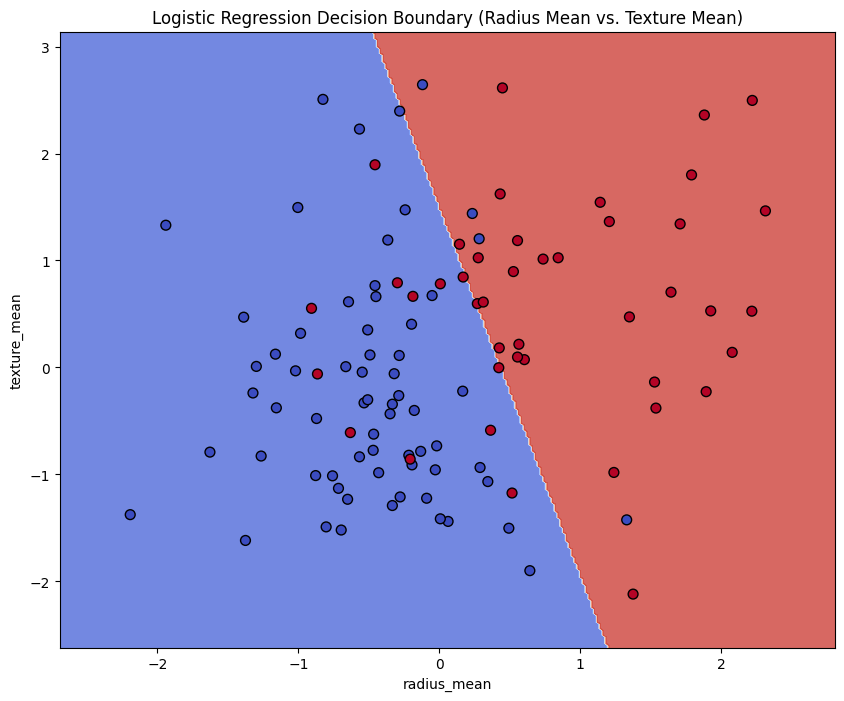

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

# Assuming 'radius_mean' is at index 1 and 'texture_mean' at index 2 in numerical_columns
# Explicitly convert X_train to a NumPy array before slicing, as it appears to be a DataFrame in the current kernel state.
X_train_2d = np.array(X_train)[:, [1, 2]] # index for 'radius_mean', index for 'texture_mean'
X_test_2d = X_test[:, [1, 2]]

# Retrain Logistic Regression model on the 2D data
log_reg_model_2d = LogisticRegression(random_state=42, max_iter=200)
log_reg_model_2d.fit(X_train_2d, y_train)

# Create a meshgrid for plotting the decision boundary
x_min, x_max = X_test_2d[:, 0].min() - 0.5, X_test_2d[:, 0].max() + 0.5
y_min, y_max = X_test_2d[:, 1].min() - 0.5, X_test_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict class labels for each point in the meshgrid
Z = log_reg_model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.coolwarm)
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test, cmap=plt.cm.coolwarm, s=50, edgecolors='k')
plt.xlabel(numerical_columns[1]) # Label with 'radius_mean'
plt.ylabel(numerical_columns[2]) # Label with 'texture_mean'
plt.title('Logistic Regression Decision Boundary (Radius Mean vs. Texture Mean)')
plt.show()